<a href="https://colab.research.google.com/github/RaniaInaya/UJI-VALIDITAS-BUTIR-DAN-RELIABILITAS/blob/main/Uji_Validitas_Reliabilitas_3TIA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Uji Validitas dan Reliabilitas - Kelas 3 TI A

## Nama : Rania Maisha Inaya
## Kelas : 3TIA
## NIM : 2455301163

## 1. Import library

In [1]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

## 2. Baca file Excel dan pilih kelas 3 TI A

In [2]:
nama_file = "Respons Gabungan 3 TI A - Versi Baru - 29 Butir.xlsx"
lokasi = Path(nama_file)
if not lokasi.exists():
    lokasi = Path('/mnt/data') / nama_file
if not lokasi.exists():
    try:
        from google.colab import files
        unggahan = files.upload()
        lokasi = Path(next(iter(unggahan)))
    except ImportError:
        raise FileNotFoundError('Letakkan file Excel di folder notebook lalu jalankan lagi.')

df_awal = pd.read_excel(lokasi, sheet_name='Jawaban Formulir 1')
df = df_awal[df_awal['Kelas'].astype(str).str.strip() == '3 TI A'].copy()
# Dua kolom awal merupakan metadata: Cap waktu dan Kelas.
butir = df.iloc[:, 2:]
print('Jumlah respons:', len(df))
print('Jumlah butir:', butir.shape[1])
print('Jumlah sel kosong:', int(butir.isna().sum().sum()))
assert butir.shape[1] == 29, 'Periksa apakah benar ada 29 butir.'
assert not butir.isna().any().any(), 'Ada jawaban kosong, cek datanya.'

Saving Respons Gabungan 3 TI A - Versi Baru - 29 Butir.xlsx to Respons Gabungan 3 TI A - Versi Baru - 29 Butir (1).xlsx
Jumlah respons: 39
Jumlah butir: 29
Jumlah sel kosong: 0


## 3. Konversi skala Likert menjadi angka

In [10]:
skala = {
    'Sangat Tidak Setuju (STS)': 1,
    'Tidak Setuju (TS)': 2,
    'Netral (N)': 3,
    'Setuju (S)': 4,
    'Sangat Setuju (SS)': 5
}
num = butir.replace(skala).apply(pd.to_numeric, errors='coerce')
print('Gagal konversi:', int(num.isna().sum().sum()))
assert not num.isna().any().any(), 'Periksa ejaan jawaban skala Likert.'
display(num.iloc[:5, :6])

Gagal konversi: 0


/tmp/ipykernel_542/3633144223.py:8: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  num = butir.replace(skala).apply(pd.to_numeric, errors='coerce')


,Penggunaan AI pada tugas atau projek kuliah [AI1. Saya menggunakan AI ketika mengerjakan tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI2. Saya menggunakan AI untuk memahami persoalan dalam tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI3. Saya menggunakan AI untuk mencari ide pengerjaan tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI4. Saya menggunakan AI untuk menyusun langkah penyelesaian tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI5. Saya menggunakan AI untuk memperoleh contoh penyelesaian tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI6. Saya menggunakan AI untuk mengembangkan jawaban tugas kuliah.]
0,1,2,4,5,4,2
1,1,2,1,5,5,4
2,1,2,1,2,2,2
3,5,4,2,1,2,4
4,5,4,2,1,2,4


## 4. Kelompokkan per dimensi dan baca kode butir

In [4]:
dimensi = {}
kode_butir = {}
pernyataan = {}
for kolom in num.columns:
    nama = re.match(r'^(.*?)\s*\[', kolom).group(1)
    kode = re.search(r'\[([A-Z]+\d+)\.', kolom).group(1)
    kalimat = re.search(r'\[[A-Z]+\d+\.\s*(.*?)\]$', kolom).group(1)
    dimensi.setdefault(nama, []).append(kolom)
    kode_butir[kolom] = kode
    pernyataan[kolom] = kalimat
for nama, kolom in dimensi.items():
    print(nama, ':', len(kolom), 'butir')

Penggunaan AI pada tugas atau projek kuliah : 7 butir
Aspek psikologis penggunaan AI pada tugas atau projek kuliah : 7 butir
Kebiasaan penggunaan teknologi digital : 6 butir
Prokrastinasi akademik : 4 butir
Respons emosional : 5 butir


## 5. Uji validitas Pearson dan corrected r

In [5]:
n = len(num)
df_t = n - 2
nilai_t = stats.t.ppf(0.975, df_t)
r_tabel = nilai_t / np.sqrt(df_t + nilai_t**2)
print(f'n={n} | df={df_t} | r-tabel={r_tabel:.3f}')

hasil_validitas = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)
    for kolom in daftar:
        r, p = stats.pearsonr(x[kolom], total)
        corrected, _ = stats.pearsonr(x[kolom], total - x[kolom])
        hasil_validitas.append({
            'Dimensi': nama,
            'Kode Butir': kode_butir[kolom],
            'r-hitung': r,
            'Corrected r': corrected,
            'p-value': p,
            'Keputusan': 'Valid' if r > r_tabel else 'Tidak valid'
        })
tabel_validitas = pd.DataFrame(hasil_validitas)
display(tabel_validitas.round(3))
print('Jumlah valid:', (tabel_validitas['Keputusan'] == 'Valid').sum())
print('Tidak valid:', tabel_validitas.loc[tabel_validitas['Keputusan'] == 'Tidak valid', 'Kode Butir'].tolist())
print('Corrected r >= 0,30:', (tabel_validitas['Corrected r'] >= 0.30).sum())

n=39 | df=37 | r-tabel=0.316


,Dimensi,Kode Butir,r-hitung,Corrected r,p-value,Keputusan
0,Penggunaan AI pada tugas atau projek kuliah,AI1,0.662,0.424,0.000,Valid
1,Penggunaan AI pada tugas atau projek kuliah,AI2,0.514,0.347,0.001,Valid
2,Penggunaan AI pada tugas atau projek kuliah,AI3,0.678,0.517,0.000,Valid
3,Penggunaan AI pada tugas atau projek kuliah,AI4,0.238,-0.030,0.145,Tidak valid
4,Penggunaan AI pada tugas atau projek kuliah,AI5,0.539,0.311,0.000,Valid
5,Penggunaan AI pada tugas atau projek kuliah,AI6,0.493,0.295,0.001,Valid
6,Penggunaan AI pada tugas atau projek kuliah,AI7,0.776,0.618,0.000,Valid
7,Aspek psikologis penggunaan AI pada tugas atau...,PS1,0.494,0.150,0.001,Valid
8,Aspek psikologis penggunaan AI pada tugas atau...,PS2,0.559,0.311,0.000,Valid
9,Aspek psikologis penggunaan AI pada tugas atau...,PS3,0.569,0.340,0.000,Valid


Jumlah valid: 26
Tidak valid: ['AI4', 'PS4', 'TD6']
Corrected r >= 0,30: 11


## 6. Uji reliabilitas Cronbach’s Alpha (per dimensi)

In [6]:
def cronbach_alpha(x):
    k = x.shape[1]
    if k < 2:
        return np.nan
    var_total = x.sum(axis=1).var(ddof=1)
    if var_total == 0:
        return np.nan
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / var_total)

def kategori_alpha(a):
    if a >= 0.90:
        return 'Sangat baik'
    if a >= 0.80:
        return 'Baik'
    if a >= 0.70:
        return 'Reliabel'
    return 'Tidak reliabel'

hasil_reliabilitas = []
hasil_hapus = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    alpha = cronbach_alpha(x)
    hasil_reliabilitas.append({
        'Dimensi': nama, 'Jumlah butir': len(daftar),
        'Cronbach Alpha': alpha, 'Kategori': kategori_alpha(alpha)
    })
    for kolom in daftar:
        if len(daftar) > 2:
            a_hapus = cronbach_alpha(x.drop(columns=kolom))
            hasil_hapus.append({'Dimensi': nama, 'Kode Butir': kode_butir[kolom], 'Alpha jika dihapus': a_hapus})
tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_hapus = pd.DataFrame(hasil_hapus)
gabungan = tabel_validitas.merge(tabel_hapus, on=['Dimensi', 'Kode Butir'], how='left')
display(tabel_reliabilitas.round(3))
display(gabungan[['Kode Butir','r-hitung','Corrected r','Alpha jika dihapus','Keputusan']].round(3))

,Dimensi,Jumlah butir,Cronbach Alpha,Kategori
0,Penggunaan AI pada tugas atau projek kuliah,7,0.630,Tidak reliabel
1,Aspek psikologis penggunaan AI pada tugas atau...,7,0.421,Tidak reliabel
2,Kebiasaan penggunaan teknologi digital,6,0.308,Tidak reliabel
3,Prokrastinasi akademik,4,0.111,Tidak reliabel
4,Respons emosional,5,0.516,Tidak reliabel


,Kode Butir,r-hitung,Corrected r,Alpha jika dihapus,Keputusan
0,AI1,0.662,0.424,0.563,Valid
1,AI2,0.514,0.347,0.595,Valid
2,AI3,0.678,0.517,0.540,Valid
3,AI4,0.238,-0.030,0.706,Tidak valid
4,AI5,0.539,0.311,0.603,Valid
5,AI6,0.493,0.295,0.607,Valid
6,AI7,0.776,0.618,0.488,Valid
7,PS1,0.494,0.150,0.412,Valid
8,PS2,0.559,0.311,0.322,Valid
9,PS3,0.569,0.340,0.312,Valid


## 7. Analisis deskriptif dan grafik jawaban

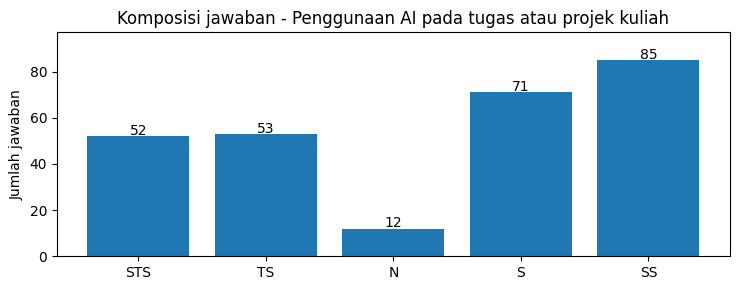

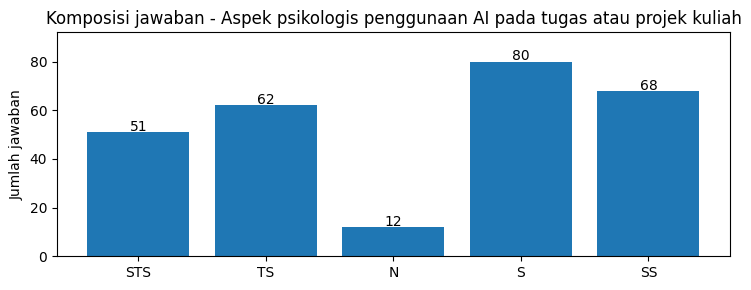

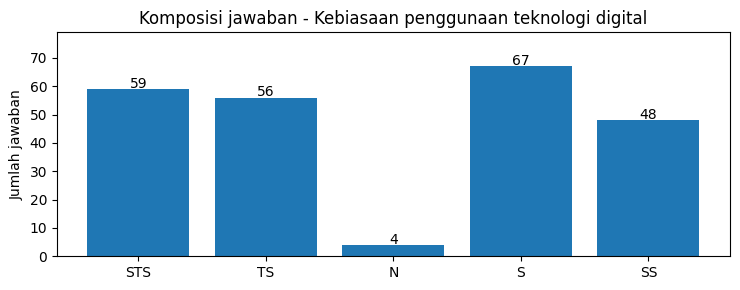

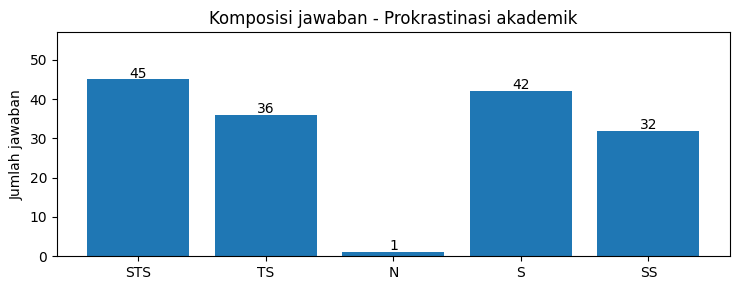

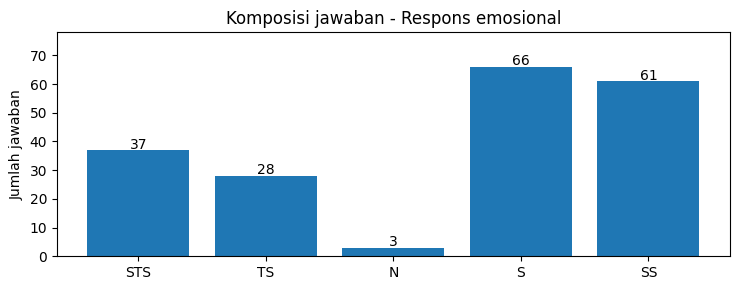

,Dimensi,Rata-rata per butir,Mean skor total,Standar deviasi skor total,Skewness,Kurtosis excess
0,Penggunaan AI pada tugas atau projek kuliah,3.308,23.154,6.015,0.149,-0.549
1,Aspek psikologis penggunaan AI pada tugas atau...,3.190,22.333,4.975,0.339,-0.277
2,Kebiasaan penggunaan teknologi digital,2.953,17.718,4.353,-0.109,0.986
3,Prokrastinasi akademik,2.872,11.487,3.276,-0.075,0.354
4,Respons emosional,3.441,17.205,4.408,0.019,-0.973


In [7]:
deskriptif = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    skor_total = x.sum(axis=1)
    deskriptif.append({
        'Dimensi': nama,
        'Rata-rata per butir': x.to_numpy().mean(),
        'Mean skor total': skor_total.mean(),
        'Standar deviasi skor total': skor_total.std(ddof=1),
        'Skewness': stats.skew(skor_total, bias=False),
        'Kurtosis excess': stats.kurtosis(skor_total, bias=False)
    })
    counts = x.stack().value_counts().reindex([1,2,3,4,5], fill_value=0)
    plt.figure(figsize=(7.5, 3))
    plt.bar(['STS','TS','N','S','SS'], counts.values)
    plt.title('Komposisi jawaban - ' + nama)
    plt.ylabel('Jumlah jawaban')
    for i, val in enumerate(counts.values):
        plt.text(i, val+0.5, str(val), ha='center')
    plt.ylim(0, max(counts.values)+12)
    plt.tight_layout()
    plt.show()
tabel_deskriptif = pd.DataFrame(deskriptif)
display(tabel_deskriptif.round(3))

## 8. Simpan hasil uji ke Excel

In [8]:
with pd.ExcelWriter('hasil_uji_validitas_reliabilitas.xlsx') as writer:
    gabungan.to_excel(writer, sheet_name='Validitas', index=False)
    tabel_reliabilitas.to_excel(writer, sheet_name='Reliabilitas', index=False)
    tabel_deskriptif.to_excel(writer, sheet_name='Deskriptif', index=False)
print('File hasil_uji_validitas_reliabilitas.xlsx berhasil disimpan.')

File hasil_uji_validitas_reliabilitas.xlsx berhasil disimpan.


## 9. Latihan tambahan dari modul (opsional)

In [9]:
# Bandingkan hasil validitas utama dengan corrected r >= 0,30
print('Valid dari r-hitung:', (tabel_validitas['Keputusan'] == 'Valid').sum())
print('Lolos corrected r >= 0,30:', (tabel_validitas['Corrected r'] >= 0.30).sum())

# Contoh mengeluarkan satu butir yang tidak valid, tanpa mengubah data asli
nama_ai = next(nm for nm in dimensi if nm.startswith('Penggunaan AI'))
x_ai = num[dimensi[nama_ai]]
kolom_ai4 = next(k for k in dimensi[nama_ai] if kode_butir[k] == 'AI4')
print('Alpha AI sebelum:', round(cronbach_alpha(x_ai), 3))
print('Alpha AI tanpa AI4:', round(cronbach_alpha(x_ai.drop(columns=kolom_ai4)), 3))

# Pengaruh jumlah sampel pada r-tabel dan jumlah butir yang lolos
subset = num.sample(20, random_state=1)
t20 = stats.t.ppf(0.975, 18)
r20 = t20 / np.sqrt(18 + t20**2)
lolos20 = sum(stats.pearsonr(subset[k], subset[daftar].sum(axis=1))[0] > r20
              for daftar in dimensi.values() for k in daftar)
print('r-tabel n=20:', round(r20, 3), '| valid:', lolos20)

Valid dari r-hitung: 26
Lolos corrected r >= 0,30: 11
Alpha AI sebelum: 0.63
Alpha AI tanpa AI4: 0.706
r-tabel n=20: 0.444 | valid: 21


**Catatan refleksi:** Instrumen yang reliabel belum tentu valid. Misalnya, beberapa butir bisa memberi jawaban yang konsisten tetapi ternyata mengukur hal berbeda dari tujuan penelitian. Hasil penghapusan butir hanya contoh perbandingan, bukan berarti jawaban responden diubah. Uji ulang perlu dilakukan jika instrumen memang diperbaiki.

## Kesimpulan

Dari 29 butir, sebanyak **26 valid** berdasarkan r-hitung Pearson dan **3 tidak valid** (AI4, PS4, TD6). Jika memakai corrected r minimal 0,30 sebagai pembanding yang lebih ketat, hanya **11 butir** memenuhi batas. Semua **5 dimensi belum reliabel** (Alpha di bawah 0,70). Butir yang rendah perlu ditinjau bersama isi pertanyaannya; tidak langsung dihapus semata-mata karena angka.